In [1]:
import os
import json
import copy
import logging
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['pdf.fonttype'] = 42
import seaborn as sns
from scipy.stats import mannwhitneyu, wilcoxon
from Bio.PDB.MMCIFParser import MMCIFParser
from Bio.PDB.SASA import ShrakeRupley
warnings.filterwarnings("ignore")
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)

In [2]:
# protein-DNA buried surface area + ipTM, high vs low motif syntax
# BSA(TF-DNA) = 0.5 * (SASA(TF) + SASA(DNA duplex) - SASA(TF+DNA)), separately for TF1 (A) and TF2 (B) vs C+D
dt = pd.read_csv("../data/tangermeme_hard_syntax_top_and_worst_motif_examples_n100_rho0.6.csv", dtype={"motif_combination": str})
manifest = dt[["motif_combination", "background_idx", "class", "TF1", "TF2"]].rename(columns={"motif_combination": "combo"})
manifest["group"] = manifest["TF1"] + "_" + manifest["TF2"] + "_" + manifest["combo"]
manifest["name"] = manifest["group"] + "_" + manifest["class"] + "_bg" + manifest["background_idx"].astype(str)
manifest["model_path"] = "../af3_screen_n100_rho0.6/outputs_inference/" + manifest["name"] + "_model.cif"
manifest["exists"] = manifest["model_path"].apply(os.path.exists)
manifest["exists"].value_counts()

exists
True    6400
Name: count, dtype: int64

In [3]:
parser = MMCIFParser(QUIET=True)
sr = ShrakeRupley(probe_radius=1.4, n_points=100)

def yy_sasa(model, keep_chains):
    """Shrake-Rupley SASA (A^2) of a copy of the model with only keep_chains."""
    m = copy.deepcopy(model)
    for ch in list(m):
        if ch.id not in keep_chains:
            m.detach_child(ch.id)
    sr.compute(m, level="A")
    return sum(a.sasa for a in m.get_atoms())

In [4]:
# slow (5 SASA calls per model, several hours), so resume from the checkpoint
checkpoint = "../results/cache/protein_dna_bsa_checkpoint.csv"
records = pd.read_csv(checkpoint).to_dict("records") if os.path.exists(checkpoint) else []
todo = manifest[manifest["exists"] & ~manifest["name"].isin({r["name"] for r in records})]
print(f"{len(records)} done, {len(todo)} to do")

for i, (_, row) in enumerate(todo.iterrows()):
    model = parser.get_structure(row["name"], row["model_path"])[0]
    sasa_a = yy_sasa(model, {"A"})
    sasa_b = yy_sasa(model, {"B"})
    sasa_dna = yy_sasa(model, {"C", "D"})
    sasa_a_dna = yy_sasa(model, {"A", "C", "D"})
    sasa_b_dna = yy_sasa(model, {"B", "C", "D"})
    records.append({
        "name": row["name"], "group": row["group"], "combo": row["combo"],
        "background_idx": row["background_idx"], "class": row["class"],
        "TF1": row["TF1"], "TF2": row["TF2"], "pair": row["TF1"] + "-" + row["TF2"],
        "SASA_TF1": sasa_a, "SASA_TF2": sasa_b, "SASA_DNA": sasa_dna,
        "SASA_TF1_DNA_complex": sasa_a_dna, "SASA_TF2_DNA_complex": sasa_b_dna,
        "BSA_TF1_DNA": 0.5 * (sasa_a + sasa_dna - sasa_a_dna),
        "BSA_TF2_DNA": 0.5 * (sasa_b + sasa_dna - sasa_b_dna),
    })
    if (i + 1) % 200 == 0 or i + 1 == len(todo):
        pd.DataFrame(records).to_csv(checkpoint, index=False)

6400 done, 0 to do


In [5]:
results = pd.DataFrame(records)
results["class"] = pd.Categorical(results["class"], categories=["high", "low"], ordered=True)
results = results[["name", "group", "combo", "background_idx", "class", "TF1", "TF2", "pair",
                   "SASA_TF1", "SASA_TF2", "SASA_DNA", "BSA_TF1_DNA", "BSA_TF2_DNA"]]

In [6]:
# TF-DNA ipTM: chain order A, B, C, D; C and D are one duplex so average A-C/A-D and B-C/B-D
def yy_dna_iptm(name):
    m = json.load(open(f"../af3_screen_n100_rho0.6/outputs_inference/{name}_summary_confidences.json"))["chain_pair_iptm"]
    return 0.5 * (m[0][2] + m[0][3]), 0.5 * (m[1][2] + m[1][3])

iptm = results["name"].apply(yy_dna_iptm)
results["iptm_TF1_DNA"] = iptm.str[0]
results["iptm_TF2_DNA"] = iptm.str[1]

In [7]:
# TF1/TF2 is not a fixed structural role here: which TF's motif sits 5' flips between groups
# (e.g. BCL11B_IKZF1_14_64 has TF2's motif 5', RUNX3_ETS1_42_64 has TF1's), so use the TF1/TF2 mean
results["DNA_BSA_mean"] = results[["BSA_TF1_DNA", "BSA_TF2_DNA"]].mean(axis=1)
results["DNA_iptm_mean"] = results[["iptm_TF1_DNA", "iptm_TF2_DNA"]].mean(axis=1)
results.to_csv("../results/tables/protein_dna_bsa_high_vs_low.csv", index=False)
results.head()

,name,group,combo,background_idx,class,TF1,TF2,pair,SASA_TF1,SASA_TF2,SASA_DNA,BSA_TF1_DNA,BSA_TF2_DNA,iptm_TF1_DNA,iptm_TF2_DNA,DNA_BSA_mean,DNA_iptm_mean
0,BCL11B_ETS1_14_64_high_bg0,BCL11B_ETS1_14_64,14_64,0,high,BCL11B,ETS1,BCL11B-ETS1,76078.185665,32386.137947,7334.143617,1433.164328,860.453482,0.725,0.91,1146.808905,0.8175
1,BCL11B_GABPA_14_64_high_bg0,BCL11B_GABPA_14_64,14_64,0,high,BCL11B,GABPA,BCL11B-GABPA,104544.681094,38011.543358,7292.106431,1692.542216,993.617087,0.750,0.92,1343.079651,0.8350
2,BCL11B_IKZF1_14_64_high_bg0,BCL11B_IKZF1_14_64,14_64,0,high,BCL11B,IKZF1,BCL11B-IKZF1,100962.817251,56764.901777,7361.812164,1462.223984,1222.501452,0.840,0.86,1342.362718,0.8500
3,RUNX1_ETS1_14_64_high_bg0,RUNX1_ETS1_14_64,14_64,0,high,RUNX1,ETS1,RUNX1-ETS1,50234.038432,42675.507126,7347.230047,703.536873,945.707793,0.920,0.94,824.622333,0.9300
4,RUNX1_GABPA_14_64_high_bg0,RUNX1_GABPA_14_64,14_64,0,high,RUNX1,GABPA,RUNX1-GABPA,49831.412986,37875.232908,7310.709434,691.761028,1029.688119,0.920,0.93,860.724573,0.9250


In [8]:
results.groupby("class", observed=True)[["DNA_BSA_mean", "DNA_iptm_mean"]].describe().T.round(3)

class                    high       low
DNA_BSA_mean  count  3200.000  3200.000
              mean    982.712   971.216
              std     209.062   190.588
              min     502.076   519.774
              25%     841.025   831.409
              50%     944.224   954.130
              75%    1065.514  1070.171
              max    1774.732  1589.343
DNA_iptm_mean count  3200.000  3200.000
              mean      0.718     0.720
              std       0.221     0.217
              min       0.162     0.182
              25%       0.528     0.512
              50%       0.812     0.825
              75%       0.913     0.910
              max       0.935     0.930

In [9]:
for metric in ["DNA_BSA_mean", "DNA_iptm_mean"]:
    high = results[results["class"] == "high"][metric]
    low = results[results["class"] == "low"][metric]
    paired = results.pivot_table(index=["group", "background_idx"], columns="class", values=metric, observed=True)
    stat, p_value = mannwhitneyu(high, low, alternative="two-sided")
    w_stat, w_p = wilcoxon(paired["high"], paired["low"], alternative="two-sided")
    print(f"{metric}: mean high = {high.mean():.3f}, mean low = {low.mean():.3f}, "
          f"Mann-Whitney p = {p_value:.3e}, paired Wilcoxon p = {w_p:.3e}")

DNA_BSA_mean: mean high = 982.712, mean low = 971.216, Mann-Whitney p = 3.651e-01, paired Wilcoxon p = 3.505e-06
DNA_iptm_mean: mean high = 0.718, mean low = 0.720, Mann-Whitney p = 3.669e-02, paired Wilcoxon p = 1.697e-06


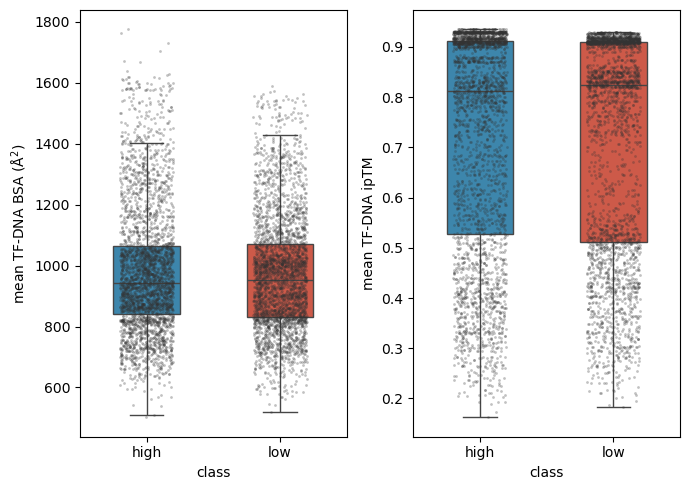

In [10]:
palette = {"high": "#2b8cbe", "low": "#e34a33"}

def yy_boxstrip(df, y, ax):
    sns.boxplot(data=df, x="class", y=y, hue="class", order=["high", "low"], palette=palette,
                width=0.5, fliersize=0, legend=False, ax=ax)
    sns.stripplot(data=df, x="class", y=y, order=["high", "low"], color="0.2", size=2, jitter=0.2, alpha=0.3, ax=ax)

fig, axes = plt.subplots(1, 2, figsize=(7, 5))
yy_boxstrip(results, "DNA_BSA_mean", axes[0])
axes[0].set_ylabel("mean TF-DNA BSA (Å$^2$)")
yy_boxstrip(results, "DNA_iptm_mean", axes[1])
axes[1].set_ylabel("mean TF-DNA ipTM")
plt.tight_layout()
plt.savefig("../results/figures/protein_dna_mean_bsa_iptm_high_vs_low.pdf", bbox_inches='tight')
plt.show()
plt.close()